# Data Exploration: Airline Delay Patterns at 20 Major U.S. Airports (2022–2026)

**Individual — Mahri Mammetmyradova**

## 1. Introduction

Flight delays are a major challenge in the U.S. aviation industry because they affect passengers, airlines, and airport operations. Delays can occur for several reasons, including airline operations, weather conditions, National Airspace System (NAS) issues, security, and late-arriving aircraft.

The purpose of this project is to explore airline delay patterns across 20 selected major U.S. airports using data from the Bureau of Transportation Statistics (BTS). The dataset covers January 2022 through July 2026 and contains airline-level monthly delay statistics.

The main research question is:

**How do airline delay patterns differ across 20 major U.S. airports, and what relationships and unusual patterns can be identified from the data?**

To answer this question, the project will use data visualization and three exploratory techniques: correlation analysis, K-means clustering, and outlier detection. These methods will help identify delay patterns, group airports with similar characteristics, and recognize unusually high delay rates.

**Data Source:** [Bureau of Transportation Statistics — Airline On-Time Performance](https://www.transtats.bts.gov/)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")


# Load the BTS airline delay dataset
df = pd.read_excel("BTS_top20_airline.xlsx")

# Preview the first five rows
df.head()


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,year_month,delay_rate,minutes_per_delayed_flight,low_sample_flag
0,2026,7,9E,Endeavor Air Inc.,ATL,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern...",3025,928,182.23,53.49,...,96739,24403,6656,19423,18,46239,2026-07,0.306777,104.244612,0
1,2026,7,9E,Endeavor Air Inc.,CLT,"Charlotte, NC: Charlotte Douglas International",225,54,19.80,0.00,...,3867,1685,0,936,0,1246,2026-07,0.240000,71.611111,0
2,2026,7,9E,Endeavor Air Inc.,DCA,"Washington, DC: Ronald Reagan Washington National",173,68,9.29,1.06,...,6397,1324,103,2692,0,2278,2026-07,0.393064,94.073529,0
3,2026,7,9E,Endeavor Air Inc.,DTW,"Detroit, MI: Detroit Metro Wayne County",1897,548,122.46,20.22,...,57284,18210,3203,2829,0,33042,2026-07,0.288877,104.532847,0
4,2026,7,9E,Endeavor Air Inc.,EWR,"Newark, NJ: Newark Liberty International",131,22,3.80,0.54,...,2111,233,29,1250,0,599,2026-07,0.167939,95.954545,0


## 2. Overview of Data Engineering Efforts

For this project, I used a previously cleaned BTS dataset containing airline delay information for 20 selected U.S. airports from January 2022 to July 2026. The original data was narrowed to focus on these airports, making the dataset easier to analyze and compare.

Before starting the analysis, I checked the dataset's size, data types, missing values, and duplicate records. I also verified the existing delay-rate calculations to make sure the data was accurate.

The dataset contains 13,472 records and 25 columns. Table 1 shows the number and percentage of missing values in each column. These checks helped me determine whether any additional data preparation was needed before creating visualizations and applying the three exploration techniques.


In [3]:

# Check dataset dimensions and data types
print("Dataset shape:", df.shape)
df.info()

# Table 1: Missing values
table1 = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percent Missing": (df.isnull().sum() / len(df) * 100).round(2)
})

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

table1


Dataset shape: (13472, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13472 entries, 0 to 13471
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   year                        13472 non-null  int64  
 1   month                       13472 non-null  int64  
 2   carrier                     13472 non-null  object 
 3   carrier_name                13472 non-null  object 
 4   airport                     13472 non-null  object 
 5   airport_name                13472 non-null  object 
 6   arr_flights                 13472 non-null  int64  
 7   arr_del15                   13472 non-null  int64  
 8   carrier_ct                  13472 non-null  float64
 9   weather_ct                  13472 non-null  float64
 10  nas_ct                      13472 non-null  float64
 11  security_ct                 13472 non-null  float64
 12  late_aircraft_ct            13472 non-null  float64
 13  arr_

,Missing Values,Percent Missing
year,0,0.00
month,0,0.00
carrier,0,0.00
carrier_name,0,0.00
airport,0,0.00
airport_name,0,0.00
arr_flights,0,0.00
arr_del15,0,0.00
carrier_ct,0,0.00
weather_ct,0,0.00


**Table 1.** Number and percentage of missing values in each column of the BTS Top 20 airline delay dataset.

The dataset used in this project was previously cleaned and narrowed to 20 selected U.S. airports. Therefore, I did not need to repeat the original cleaning process. Instead, I checked the prepared dataset for missing values, duplicate records, and consistency in the calculated delay rates.

The results in Table 1 show that 24 of the 25 columns have no missing values. The only exception is `minutes_per_delayed_flight`, which has 204 missing values (1.51%). Before performing the analysis, I will verify whether these missing values correspond to records with no delayed arrivals. I will also check the existing calculations to make sure the dataset is suitable for visualization and statistical exploration.


In [4]:

# Check duplicate airline-airport-month records
duplicates = df.duplicated(
    subset=["year", "month", "carrier", "airport"]
).sum()

# Check records with zero arriving flights
zero_flights = (df["arr_flights"] == 0).sum()

# Check missing average delay minutes
missing_delay = df[df["minutes_per_delayed_flight"].isna()]
zero_delays = (missing_delay["arr_del15"] == 0).sum()


# Verify the existing delay rate
valid = df["arr_flights"] > 0

calculated_rate = (
    df.loc[valid, "arr_del15"] /
    df.loc[valid, "arr_flights"]
)

rate_difference = (
    calculated_rate - df.loc[valid, "delay_rate"]
).abs()


rate_difference = (
    calculated_rate - df.loc[valid, "delay_rate"]
).abs()

print("Duplicate record keys:", duplicates)
print("Zero-flight records:", zero_flights)
print("Missing average delay values:", len(missing_delay))
print("Missing averages with zero delays:", zero_delays)
print("Maximum delay-rate difference:", rate_difference.max())


Duplicate record keys: 0
Zero-flight records: 0
Missing average delay values: 204
Missing averages with zero delays: 204
Maximum delay-rate difference: 5.000000000143778e-07


The validation results showed no duplicate records or zero-flight observations. All 204 missing average delay values occurred in records with zero delayed arrivals, so these values were left missing rather than replaced with zero. I also verified the delay-rate calculations and found only a very small difference of approximately 0.0000005, which is consistent with rounding.

## 3. Data Visualization

This section explores airline delay patterns across 20 selected U.S. airports from January 2022 to July 2026. The visualizations examine differences in delay rates, trends over time, and the main categories of delays. These findings will help identify patterns that can be explored further through correlation analysis, K-means clustering, and outlier detection.


### Improvements from Previous Assignment

Compared with my previous assignment, I focused on making the visualizations clearer and easier to interpret. I narrowed the analysis to 20 selected U.S. airports and used delay percentages instead of only raw delay counts to make comparisons more meaningful. I also improved the graphs by organizing the airports by delay rate and using clearer labels and colors. These changes help show differences in airline delays more clearly and support my project's research goals.

### 3.1 Monthly Delay Trends by Year

This visualization compares monthly airline delay rates across different years to identify seasonal patterns and changes in delay performance over time.

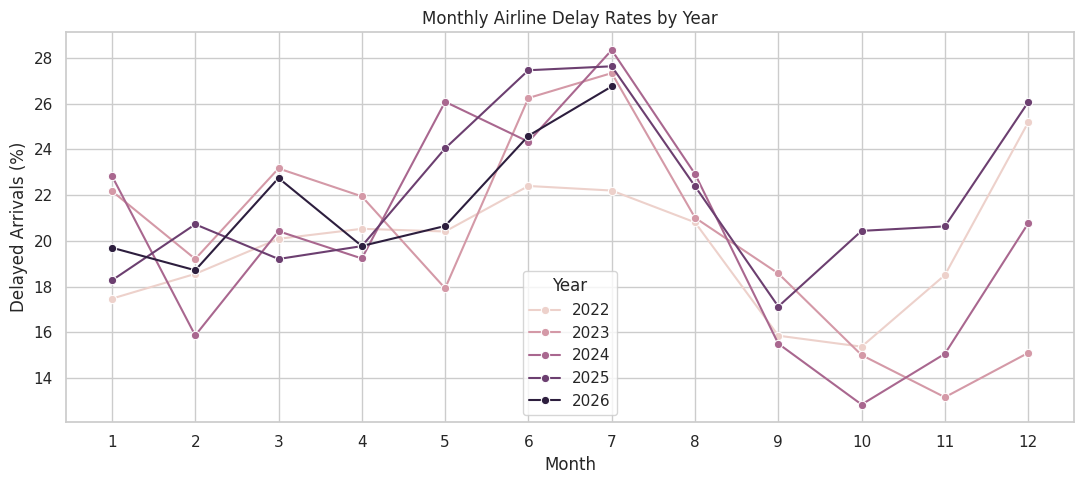

In [5]:

# Figure 1: Monthly delay trends by year
monthly = (
    df.groupby(["year", "month"], as_index=False)
    [["arr_del15", "arr_flights"]]
    .sum()
)

monthly["delay_rate"] = (
    monthly["arr_del15"] / monthly["arr_flights"] * 100
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=monthly,
    x="month",
    y="delay_rate",
    hue="year",
    marker="o"
)

plt.title("Monthly Airline Delay Rates by Year")
plt.xlabel("Month")
plt.ylabel("Delayed Arrivals (%)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()


**Figure 1.** Monthly delayed-arrival rates across the 20 selected U.S. airports, grouped by year (2022–2026).

The monthly delay trends show that airline delays tend to increase during the summer months, particularly June and July, when delayed arrivals reach approximately 27–28% in some years. Delay rates generally decrease during the fall, especially between September and November, although the patterns vary across years. These results suggest that airline delays have seasonal characteristics, with summer showing higher delay rates in several years. The differences between years also indicate that delay performance is not consistent over time. Since the 2026 data only extends through July, comparisons involving that year are limited to the available months.

### 3.2 Airline Delay Rates

This visualization compares delayed-arrival percentages across airlines operating at the 20 selected U.S. airports. Comparing airline performance helps identify differences in delay rates and determine which airlines experience relatively higher or lower levels of delays.

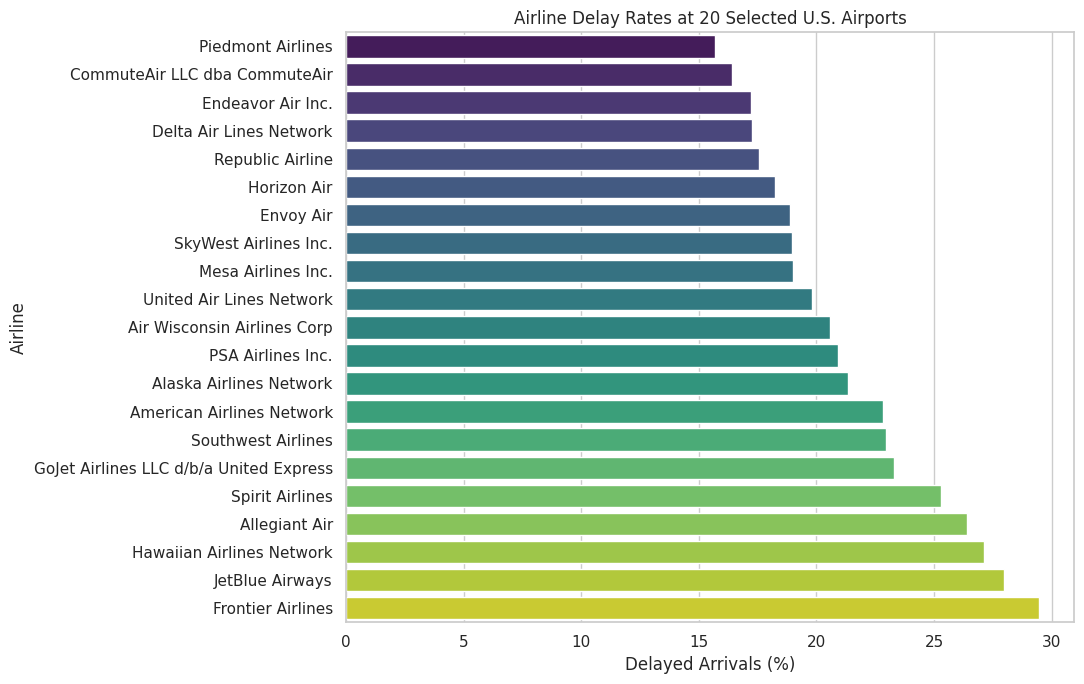

In [6]:


# Figure 2: Airline delay rates

# Use one consistent name for each airline code
carrier_names = (
    df.sort_values(["year", "month"])
    .groupby("carrier")["carrier_name"]
    .last()
)

# Calculate delay rates by airline code
airline_summary = (
    df.groupby("carrier")[["arr_del15", "arr_flights"]]
    .sum()
    .reset_index()
)

airline_summary["delay_rate"] = (
    airline_summary["arr_del15"] /
    airline_summary["arr_flights"] * 100
)

# Add airline names and sort by delay rate
airline_summary["carrier_name"] = (
    airline_summary["carrier"].map(carrier_names)
)

airline_summary = airline_summary.sort_values("delay_rate")

# Create the visualization
plt.figure(figsize=(11, 7))

sns.barplot(
    data=airline_summary,
    x="delay_rate",
    y="carrier_name",
    hue="carrier_name",
    palette="viridis",
    dodge=False,
    legend=False
)

plt.title("Airline Delay Rates at 20 Selected U.S. Airports")
plt.xlabel("Delayed Arrivals (%)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()


**Figure 2.** Percentage of arriving flights delayed by at least 15 minutes for each airline across the 20 selected U.S. airports (January 2022–July 2026).

The airline comparison shows differences in delay performance among carriers operating at the 20 selected airports. Frontier Airlines has the highest delayed-arrival percentage at approximately 29.5%, followed by JetBlue Airways and Hawaiian Airlines. Piedmont Airlines has the lowest rate at approximately 15.7%. These results suggest that delay performance varies among airlines. However, differences in routes, airport locations, and flight volumes may influence these comparisons, so the results should not be interpreted as evidence that one airline is inherently more reliable than another.

*I also found that one airline was listed under two different names, so I used the airline code to combine its records and ensure that each airline appeared only once in the comparison.*

### 3.3 Airport Delay Rate Comparison

This visualization compares delayed-arrival percentages across the 20 selected U.S. airports. The goal is to identify which airports experience relatively higher or lower delay rates and examine differences in airport performance.

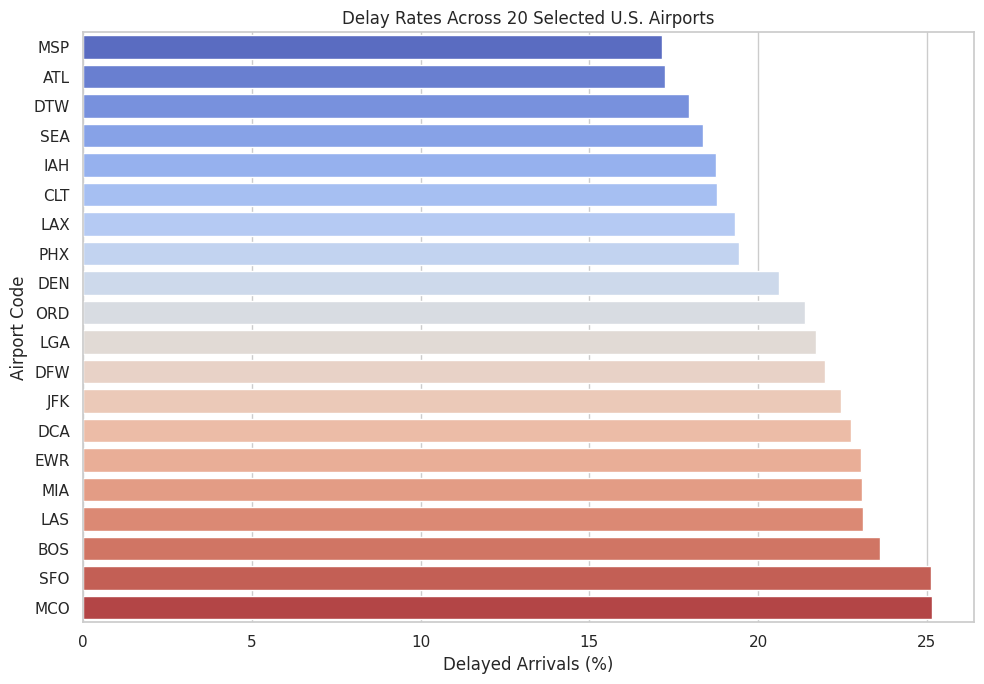

In [7]:

# Figure 3: Airport delay rate comparison

airport_summary = (
    df.groupby("airport")[["arr_del15", "arr_flights"]]
    .sum()
    .reset_index()
)

airport_summary["delay_rate"] = (
    airport_summary["arr_del15"] /
    airport_summary["arr_flights"] * 100
)

airport_summary = airport_summary.sort_values("delay_rate")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=airport_summary,
    x="delay_rate",
    y="airport",
    hue="airport",
    palette="coolwarm",
    dodge=False,
    legend=False
)

plt.title("Delay Rates Across 20 Selected U.S. Airports")
plt.xlabel("Delayed Arrivals (%)")
plt.ylabel("Airport Code")

plt.tight_layout()
plt.show()


**Figure 3.** Comparison of delayed-arrival percentages across the 20 selected U.S. airports from January 2022 to July 2026.

Figure 3 shows noticeable differences in delay rates across the 20 selected airports. Orlando (MCO) and San Francisco (SFO) have the highest percentages of delayed arrivals, at approximately 25%, while Minneapolis–Saint Paul (MSP) has the lowest rate, at approximately 17%. Boston (BOS) also shows a relatively high delay rate, while Atlanta (ATL) and Detroit (DTW) have relatively lower rates. These differences suggest that airline delay performance varies by airport, although additional analysis is needed to understand the factors associated with these patterns.

### 3.4 Delay Causes by Airline

This visualization compares the distribution of airline-related, weather-related, NAS-related, security-related, and late-aircraft delays across airlines. The goal is to understand how the composition of reported delay causes differs between carriers.

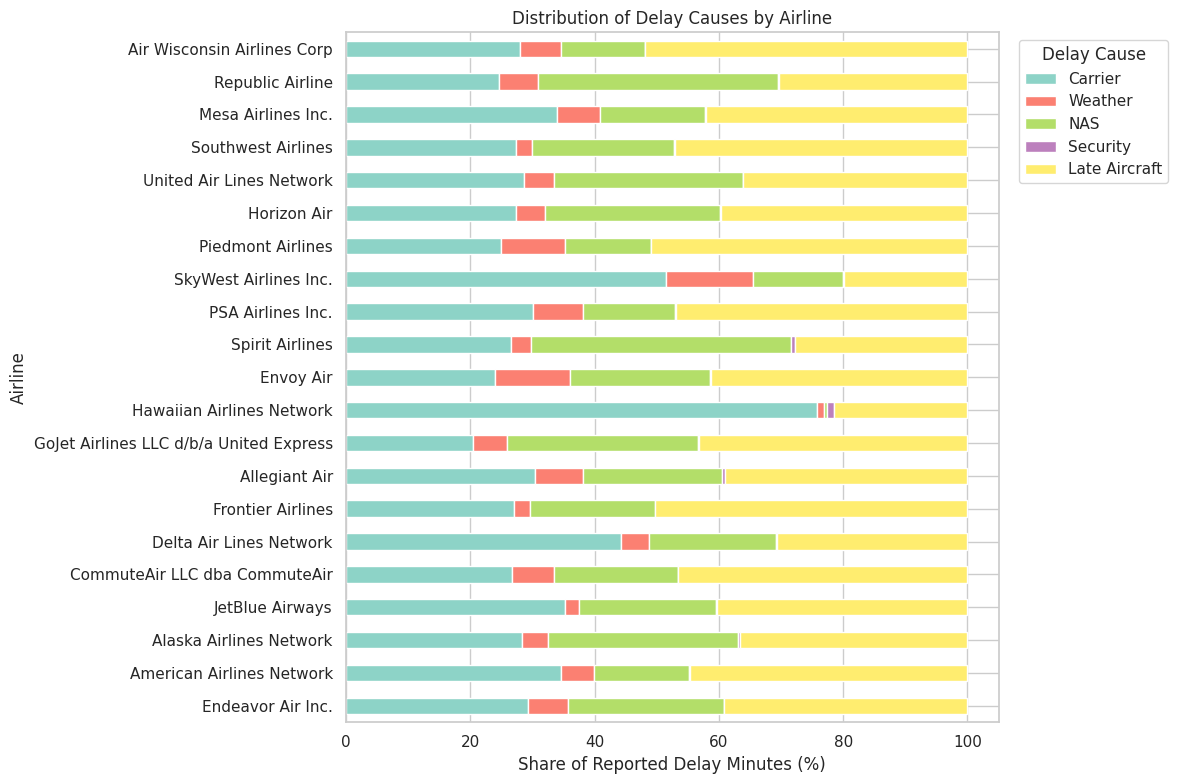

In [8]:

# Figure 4: Delay causes by airline

cause_columns = [
    "carrier_delay",
    "weather_delay",
    "nas_delay",
    "security_delay",
    "late_aircraft_delay"
]

airline_causes = df.groupby("carrier")[cause_columns].sum()

# Convert delay minutes to percentages
airline_causes = (
    airline_causes.div(airline_causes.sum(axis=1), axis=0) * 100
)

# Use consistent airline names from Figure 4
airline_causes.index = airline_causes.index.map(carrier_names)

airline_causes = airline_causes.rename(columns={
    "carrier_delay": "Carrier",
    "weather_delay": "Weather",
    "nas_delay": "NAS",
    "security_delay": "Security",
    "late_aircraft_delay": "Late Aircraft"
})

airline_causes.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    colormap="Set3"
)

plt.title("Distribution of Delay Causes by Airline")
plt.xlabel("Share of Reported Delay Minutes (%)")
plt.ylabel("Airline")
plt.legend(title="Delay Cause", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Figure 4.** Percentage distribution of reported delay minutes by cause for each airline operating at the 20 selected U.S. airports (January 2022–July 2026).

## 4. Data Exploration Techniques

### 4.1 Correlation Analysis

Correlation analysis is used to examine relationships between numerical variables. I selected this technique to investigate how different airline delay categories are associated with overall delay rates. Unlike visual comparisons that focus on individual airports or airlines, correlation analysis measures the strength and direction of relationships between variables.

This method is relevant to my project because it can help identify which delay measurements are most closely associated with overall delay performance. However, correlation does not establish causation, so the results will be interpreted as statistical relationships rather than evidence that one delay category directly causes another.

Records used: 12881
Records excluded: 591


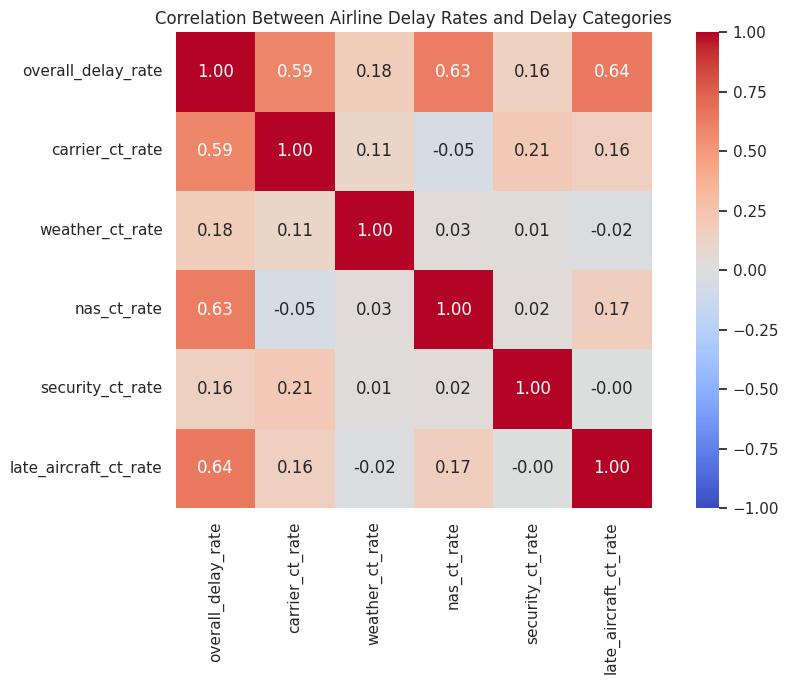

In [9]:


# Figure 5: Correlation between delay variables

# Exclude records with fewer than 20 arriving flights
correlation_df = df[
    (df["arr_flights"] > 0) &
    (df["low_sample_flag"] == 0)
].copy()

print("Records used:", len(correlation_df))
print("Records excluded:", len(df) - len(correlation_df))

# Calculate delay rates per 100 arriving flights
correlation_df["overall_delay_rate"] = (
    correlation_df["arr_del15"] /
    correlation_df["arr_flights"] * 100
)

cause_counts = [
    "carrier_ct",
    "weather_ct",
    "nas_ct",
    "security_ct",
    "late_aircraft_ct"
]

for cause in cause_counts:
    correlation_df[cause + "_rate"] = (
        correlation_df[cause] /
        correlation_df["arr_flights"] * 100
    )

# Select variables for correlation analysis
rate_columns = [
    "overall_delay_rate",
    "carrier_ct_rate",
    "weather_ct_rate",
    "nas_ct_rate",
    "security_ct_rate",
    "late_aircraft_ct_rate"
]

correlation_matrix = correlation_df[rate_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Airline Delay Rates and Delay Categories")
plt.tight_layout()
plt.show()



**Figure 5.** Correlation heatmap showing how overall airline delay rates are related to different delay causes. Higher values indicate stronger relationships, while values closer to zero indicate weaker relationships.

The correlation analysis shows that overall delay rates have the strongest positive relationships with late-aircraft delays (r = 0.64), NAS delays (r = 0.63), and carrier delays (r = 0.59). Weather (r = 0.18) and security delays (r = 0.16) show weaker relationships. I excluded 591 records with fewer than 20 arriving flights to avoid unreliable percentages from small samples. These findings help identify which delay categories are most closely associated with overall delays. However, correlation does not prove causation because the delay categories contribute to the overall delay measure. I can use these results to guide further comparisons of airport delay patterns.

### 4.2 K-means Clustering

K-means clustering groups observations based on similarities in their numerical characteristics. I selected this method because I want to identify airports with similar delay patterns rather than only compare their overall delay rates. Unlike correlation analysis, which measures relationships between variables, clustering identifies groups of airports with similar characteristics.

For this analysis, I used five delay-cause rates to group the 20 selected airports based on their delay patterns. I standardized the variables before clustering so differences in their numerical scales would not dominate the results.

In [10]:

# Prepare airport-level data for K-means clustering
cluster_columns = [
    "arr_flights",
    "arr_del15",
    "carrier_ct",
    "weather_ct",
    "nas_ct",
    "security_ct",
    "late_aircraft_ct"
]

airport_cluster = df.groupby("airport")[cluster_columns].sum()

# Calculate overall and cause-specific delay rates
airport_cluster["delay_rate"] = (
    airport_cluster["arr_del15"] /
    airport_cluster["arr_flights"] * 100
)

for cause in [
    "carrier_ct", "weather_ct", "nas_ct",
    "security_ct", "late_aircraft_ct"
]:
    airport_cluster[cause + "_rate"] = (
        airport_cluster[cause] /
        airport_cluster["arr_flights"] * 100
    )

# Select clustering features
features = [
    "carrier_ct_rate",
    "weather_ct_rate",
    "nas_ct_rate",
    "security_ct_rate",
    "late_aircraft_ct_rate"
]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(airport_cluster[features])

airport_cluster[["delay_rate"] + features].round(2)


,delay_rate,carrier_ct_rate,weather_ct_rate,nas_ct_rate,security_ct_rate,late_aircraft_ct_rate
airport,,,,,,
ATL,17.25,5.49,0.66,4.39,0.03,6.67
BOS,23.61,6.79,0.62,8.23,0.05,7.93
CLT,18.78,4.97,0.89,4.67,0.05,8.20
DCA,22.77,5.63,0.69,8.23,0.05,8.16
DEN,20.62,6.55,0.74,6.41,0.03,6.89
DFW,21.98,6.17,1.39,5.74,0.06,8.61
DTW,17.94,7.11,1.19,3.63,0.04,5.98
EWR,23.06,5.36,0.72,11.26,0.03,5.69
IAH,18.74,5.99,0.69,6.21,0.02,5.82


In [11]:

from sklearn.metrics import silhouette_score

# Compare K-means models with 2 to 6 clusters
scores = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)

# Choose the number of clusters with the highest score
best_k = np.argmax(scores) + 2

print("Silhouette scores:")
for k, score in zip(range(2, 7), scores):
    print(f"{k} clusters: {score:.3f}")

print("\nSelected number of clusters:", best_k)


Silhouette scores:
2 clusters: 0.205
3 clusters: 0.232
4 clusters: 0.257
5 clusters: 0.252
6 clusters: 0.224

Selected number of clusters: 4


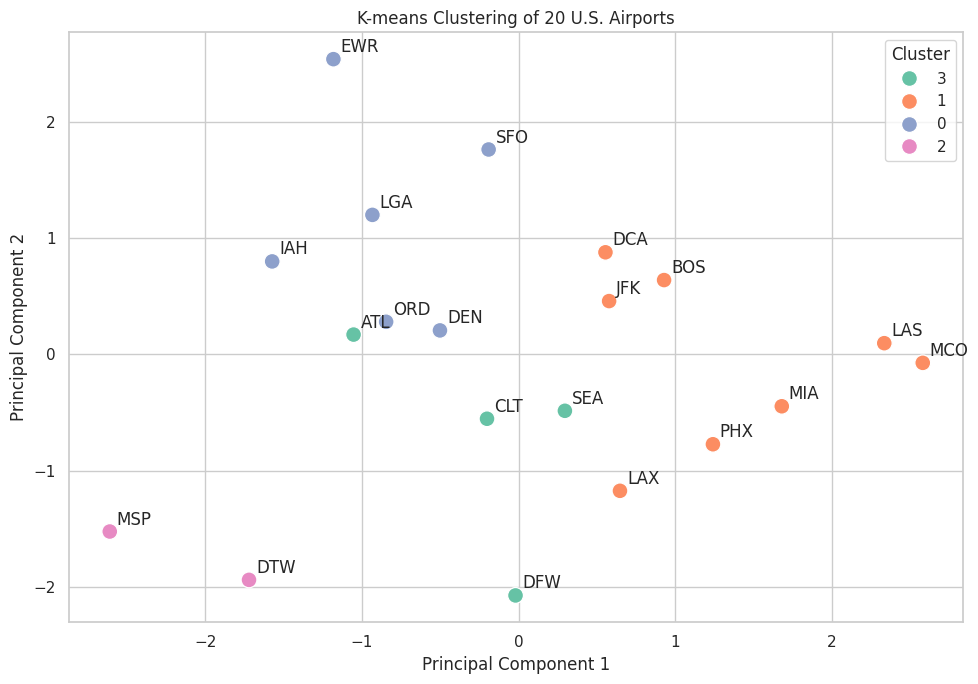

In [12]:

from sklearn.decomposition import PCA

# Fit K-means using the selected number of clusters
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

airport_cluster["cluster"] = kmeans.fit_predict(X_scaled)

# Reduce five variables to two for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "airport": airport_cluster.index,
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": airport_cluster["cluster"].astype(str).values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=130
)

# Label each airport
for _, row in plot_df.iterrows():
    plt.annotate(
        row["airport"],
        (row["PC1"], row["PC2"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("K-means Clustering of 20 U.S. Airports")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


**Figure 6.** K-means clustering of 20 selected U.S. airports using standardized delay-cause rates. The five clustering variables are displayed in two dimensions using Principal Component Analysis (PCA). Four clusters were selected based on the highest silhouette score (0.257) among the tested solutions.


In [13]:

# Table 2: K-means cluster summary

cluster_summary = (
    airport_cluster.groupby("cluster")
    [["delay_rate"] + features]
    .mean()
    .round(2)
)

cluster_summary["Number of Airports"] = (
    airport_cluster.groupby("cluster").size()
)

cluster_summary["Airports"] = (
    airport_cluster.groupby("cluster")
    .apply(lambda group: ", ".join(group.index), include_groups=False)
)

cluster_summary


,delay_rate,carrier_ct_rate,weather_ct_rate,nas_ct_rate,security_ct_rate,late_aircraft_ct_rate,Number of Airports,Airports
cluster,,,,,,,,
0,21.78,6.16,0.76,8.47,0.03,6.36,6,"DEN, EWR, IAH, LGA, ORD, SFO"
1,22.36,6.78,0.61,7.03,0.06,7.88,8,"BOS, DCA, JFK, LAS, LAX, MCO, MIA, PHX"
2,17.55,6.96,1.20,3.70,0.03,5.65,2,"DTW, MSP"
3,19.10,5.56,0.92,5.12,0.06,7.44,4,"ATL, CLT, DFW, SEA"


**Table 2.** Average overall delay rate and delay-cause rates for each K-means cluster, including the number of airports and airport codes in each group. All rates are expressed as percentages.

The K-means analysis divided the 20 airports into four groups based on their delay-cause rates. I tested different numbers of clusters using silhouette scores, and four clusters had the highest score of 0.257. However, this score suggests that the groups are not strongly separated. MSP and DTW were grouped together and had relatively low overall delay rates, while airports such as MCO, BOS, and LAS belonged to another group with higher delay rates. This analysis helps identify airports that have similar delay patterns instead of comparing every airport separately. For the remainder of my project, I can use these groups to examine differences in delay causes and better understand airport performance.

### 4.3 Outlier Detection

I selected the Interquartile Range (IQR) method to identify unusually high or low monthly airport delay rates. Unlike K-means clustering, which groups airports based on similar characteristics, outlier detection focuses on observations that differ significantly from the rest of the data. I chose the IQR method because it is simple and does not require normally distributed data.

For this analysis, I calculated monthly delay rates for each of the 20 airports. This allows me to identify unusual months that might not be noticeable when looking only at each airport's overall delay rate.

In [14]:


# Technique 3: Outlier detection by airport and month

# Calculate monthly delay rates for each airport
airport_month = (
    df.groupby(["airport", "year", "month"], as_index=False)
    [["arr_flights", "arr_del15"]]
    .sum()
)

airport_month = airport_month[
    airport_month["arr_flights"] > 0
].copy()

airport_month["delay_rate"] = (
    airport_month["arr_del15"] /
    airport_month["arr_flights"] * 100
)

# Calculate IQR boundaries
Q1 = airport_month["delay_rate"].quantile(0.25)
Q3 = airport_month["delay_rate"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify unusual airport-month observations
outliers = airport_month[
    (airport_month["delay_rate"] < lower_bound) |
    (airport_month["delay_rate"] > upper_bound)
].copy()

outliers = outliers.sort_values(
    "delay_rate", ascending=False
)

print(f"Lower bound: {lower_bound:.2f}%")
print(f"Upper bound: {upper_bound:.2f}%")
print(f"Number of outliers: {len(outliers)}")



Lower bound: 5.45%
Upper bound: 35.82%
Number of outliers: 14


In [15]:

# Table 3: Airport-month outliers

outlier_table = outliers[
    ["airport", "year", "month", "delay_rate"]
].copy()

outlier_table["delay_rate"] = (
    outlier_table["delay_rate"].round(2)
)

outlier_table


,airport,year,month,delay_rate
1098,SFO,2026,6,50.64
1099,SFO,2026,7,46.82
1097,SFO,2026,5,45.69
425,EWR,2025,5,44.66
1072,SFO,2024,4,43.26
1071,SFO,2024,3,42.19
1073,SFO,2024,5,41.34
733,MCO,2023,7,40.40
1096,SFO,2026,4,40.03
1070,SFO,2024,2,38.23


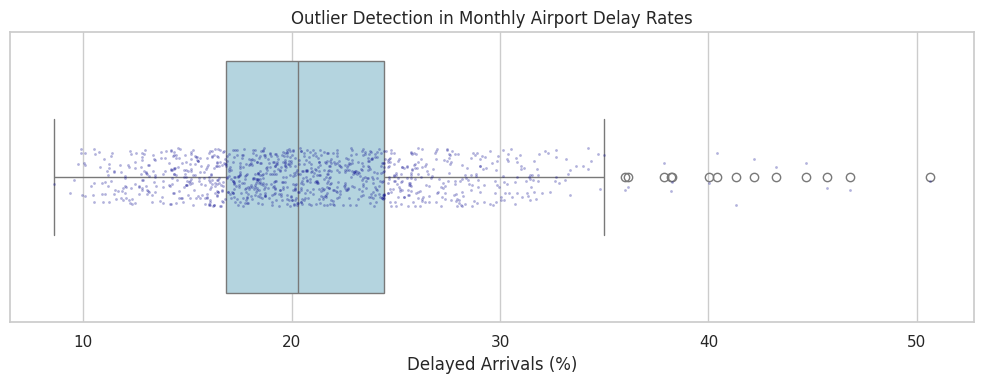

In [16]:


# Figure 7: Airport-month delay rate outlier detection

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=airport_month["delay_rate"],
    color="lightblue",
    showfliers=True
)

sns.stripplot(
    x=airport_month["delay_rate"],
    color="darkblue",
    size=2,
    alpha=0.3
)

plt.title("Outlier Detection in Monthly Airport Delay Rates")
plt.xlabel("Delayed Arrivals (%)")
plt.tight_layout()
plt.show()



**Figure 7.** Distribution of monthly delayed-arrival percentages across 20 selected U.S. airports. Potential outliers are identified using the 1.5 × IQR method.

The outlier detection analysis identified 14 unusual airport-month observations, with eight occurring at San Francisco International Airport (SFO). These results suggest that some airports experience unusually high or low delay rates during specific months, even when their overall performance appears normal. Analyzing monthly data instead of overall airport averages helped reveal these differences. For my final project, I can investigate these unusual months more closely and compare their delay causes to understand what may be associated with the higher delay rates. This will help me identify

## 5. Conclusion

This data exploration helped me better understand airline delay patterns across 20 selected U.S. airports from January 2022 to July 2026. The visualizations showed that delay rates vary across airports and tend to increase during the summer months. I also found that different airlines experience different combinations of delay causes.

The three exploration techniques provided additional insights. Correlation analysis showed that carrier, NAS, and late-aircraft delays have the strongest positive relationships with overall delay rates. K-means clustering identified four groups of airports with similar delay characteristics, although the groups were not strongly separated. Outlier detection identified 14 unusual airport-month observations, including eight at San Francisco International Airport (SFO).

For the remainder of my project, I plan to investigate seasonal delay patterns and examine why certain airports experience unusually high delay rates during specific months. I will also compare the airports within each cluster and explore how different delay causes relate to their performance. These findings will help me focus my final analysis on the most important patterns and better understand differences in airport delays.